# Rôle 3 : extraction des critères qualitatifs (`extract`)

`extract(document)` donne trois notes de 1 à 5 à partir du texte d'un projet, avec une phrase de justification par critère :

- `impact_env_social` : bénéfices environnementaux et sociaux attendus ;
- `alignement_strategique` : cohérence avec les priorités de développement ;
- `faisabilite` : capacité du projet à être mis en œuvre comme prévu.

**Difficulté principale : il n'existe pas de vérité terrain.** Personne n'a noté ces projets sur ces critères. On l'a donc construite :

1. une grille de notation écrite (`reports/role3/grille_notation.md`), qui définit chaque note ;
2. des notes de référence à la main selon la grille, pour la validation et le test ;
3. des notes automatiques par un LLM local, pour avoir assez d'exemples d'apprentissage.

Plan : données et séparation, accord entre le LLM et les notes de référence, choix du modèle sur la validation, résultats sur le test, interprétabilité, analyse des erreurs, vitesse, limites.

In [1]:
import json
import logging
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import cohen_kappa_score, confusion_matrix

RACINE = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(RACINE))
sys.path.insert(0, str(RACINE / "scripts"))
from src import nlp
import evaluer_extract_nlp as ev

FIGURES = RACINE / "reports" / "role3" / "figures"
ANNOT = RACINE / "reports" / "role3" / "annotations"
RES = RACINE / "reports" / "role3"
C = list(nlp.CRITERES_TEXTE)
NOMS = {"impact_env_social": "Impact", "alignement_strategique": "Alignement", "faisabilite": "Faisabilité"}
logging.basicConfig(level=logging.WARNING)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Données et séparation

La séparation a été fixée **avant** toute annotation et tout modèle (`scripts/separer_jeux_nlp.py`, graine 42, stratifiée par secteur). Le vocabulaire TF-IDF n'est appris que sur l'entraînement. Le test n'est utilisé qu'une fois, après le choix du modèle.

In [2]:
jeux = pd.read_csv(ANNOT / "jeux_extract.csv")
llm = pd.read_csv(ANNOT / "notes_llm.csv").set_index("id_projet")
val = pd.read_csv(ANNOT / "validation_reference.csv")
test = pd.read_csv(ANNOT / "test_reference.csv")
pd.DataFrame({
    "documents": [640, 160, 100],
    "notes": ["LLM local (qwen2.5:3b)", "à la main, selon la grille", "à la main, selon la grille"],
    "usage": ["apprendre la régression logistique", "régler et choisir le modèle", "mesure finale, une seule fois"],
}, index=["entraînement", "validation", "test"])

,documents,notes,usage
entraînement,640,LLM local (qwen2.5:3b),apprendre la régression logistique
validation,160,"à la main, selon la grille",régler et choisir le modèle
test,100,"à la main, selon la grille","mesure finale, une seule fois"


## 2. Le LLM note-t-il comme la grille ?

Le LLM (`qwen2.5:3b`, local, `scripts/annoter_llm_nlp.py`) a reçu la même grille, traduite en anglais. On compare ses notes aux notes de référence sur les 260 documents de validation et de test.

Le **kappa pondéré quadratique** mesure l'accord entre deux notateurs en tenant compte du hasard : 0 = pas mieux que le hasard, 1 = accord parfait. Il pénalise plus un écart de 2 points qu'un écart de 1.

,kappa LLM / référence (260 documents)
Impact,0.38
Alignement,0.51
Faisabilité,0.52


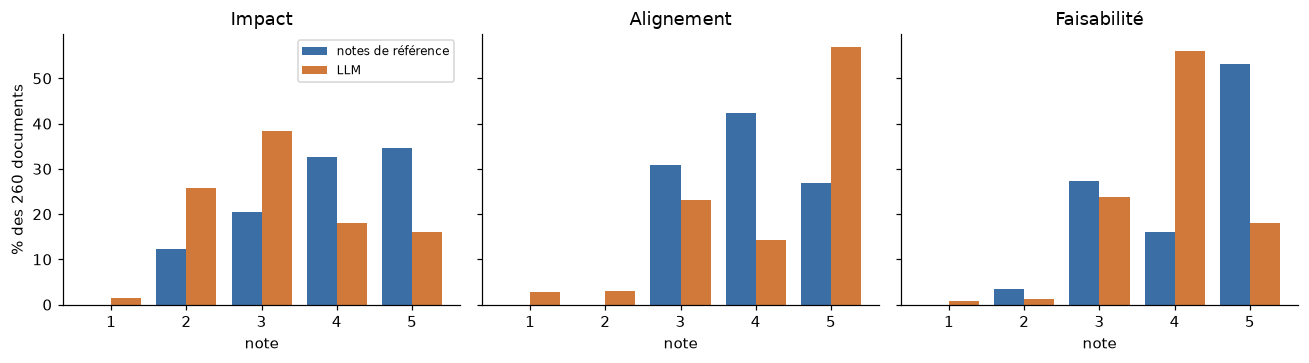

In [3]:
ref = pd.concat([val, test])
notes_llm_ref = llm.loc[ref.id_projet, C].reset_index(drop=True)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, c in zip(axes, C):
    h = ref[c].value_counts(normalize=True).reindex(range(1, 6), fill_value=0) * 100
    l = notes_llm_ref[c].value_counts(normalize=True).reindex(range(1, 6), fill_value=0) * 100
    x = np.arange(1, 6)
    ax.bar(x - 0.2, h, width=0.4, color="#3b6ea5", label="notes de référence")
    ax.bar(x + 0.2, l, width=0.4, color="#d1793b", label="LLM")
    ax.set(title=NOMS[c], xlabel="note", xticks=x)
axes[0].set_ylabel("% des 260 documents")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "extract_llm_contre_reference.png", bbox_inches="tight")
pd.Series({NOMS[c]: cohen_kappa_score(ref[c], notes_llm_ref[c], weights="quadratic") for c in C},
          name="kappa LLM / référence (260 documents)").round(2).to_frame()

**Lecture.** L'accord est modéré (kappa de 0,38 à 0,52), et surtout **le LLM n'utilise pas l'échelle de la même façon** : il met 5 en alignement à plus de la moitié des documents (contre environ un quart pour les notes de référence), donne plus de 2 et de 3 en impact, et met surtout 4 en faisabilité là où la référence met surtout 5. Un modèle appris sur ses notes imitera ces habitudes.

C'est pourquoi la validation est notée à la main. Une première tentative, avec une validation notée par le LLM, avait choisi le modèle qui imitait le mieux le LLM, et ce modèle s'était révélé moins bon sur les notes de référence.

## 3. Candidats et choix sur la validation

Cinq candidats, tous réglés sur les 160 documents de validation (`scripts/evaluer_extract_nlp.py`) :

| Candidat | Principe |
|---|---|
| `mots_cles` (référence simple) | on compte les mots-clés positifs et négatifs de la grille ; le solde donne la note par des seuils réglés sur la validation |
| `tfidf_llm` | TF-IDF (mots et paires de mots) + régression logistique, apprise sur les 640 notes du LLM ; régularisation `C` réglée sur la validation |
| `tfidf_llm_recale` | le même modèle, dont la note attendue est recalée sur l'échelle de référence (seuils qui redonnent la répartition des notes de la validation) |
| `combinaison` | moyenne du solde de mots-clés et de la note attendue TF-IDF, chacun centré-réduit, puis recalée de la même façon |
| `tfidf_humain` | TF-IDF + régression logistique apprise directement sur les 160 notes de référence, score estimé par validation croisée à 5 plis |

**Règle de choix, fixée avant d'ouvrir le test** : le meilleur kappa moyen sur la validation ; si un modèle plus simple fait presque aussi bien (moins de 0,02 d'écart), on garde le plus simple.

In [4]:
choix = json.loads((RES / "choix_extract.json").read_text(encoding="utf-8"))
rv = pd.read_csv(RES / "resultats_extract_validation.csv")
tableau_val = rv.pivot(index="modele", columns="critere", values="kappa")[C + ["moyenne"]].rename(columns=NOMS)
tableau_val = tableau_val.loc[list(ev.ORDRE_SIMPLICITE)]
print("Modèle retenu par la règle :", choix["modele_retenu"])
tableau_val.round(3)

Modèle retenu par la règle : combinaison


critere,Impact,Alignement,Faisabilité,moyenne
modele,,,,
mots_cles,0.510,0.491,0.804,0.602
tfidf_llm,0.441,0.445,0.673,0.520
tfidf_llm_recale,0.564,0.375,0.645,0.528
combinaison,0.583,0.580,0.784,0.649
tfidf_humain,0.549,0.571,0.768,0.629


La combinaison est la meilleure sur la validation (0,649), avec plus de 0,02 d'avance sur tous les autres : c'est le modèle livré dans `src/nlp.py`.

## 4. Résultats sur le test (100 documents, ouvert une seule fois)

Tous les candidats sont mesurés, avec deux points de comparaison : la classe majoritaire (toujours la note la plus fréquente) et le LLM lui-même. Pour tous, un texte de moins de 15 mots reçoit la note neutre 3.

In [5]:
rt = pd.read_csv(RES / "resultats_extract_test.csv")
ordre = ["majoritaire", "mots_cles", "tfidf_llm", "tfidf_llm_recale", "tfidf_humain", "llm", "combinaison"]
kappa_test = rt.pivot(index="modele", columns="critere", values="kappa")[C + ["moyenne"]].rename(columns=NOMS).loc[ordre]
autres = rt[rt.critere == "moyenne"].set_index("modele")[["exactitude", "mae"]].loc[ordre]
kappa_test.join(autres.rename(columns={"exactitude": "exactitude moy.", "mae": "MAE moy."})).round(3)

,Impact,Alignement,Faisabilité,moyenne,exactitude moy.,MAE moy.
modele,,,,,,
majoritaire,0.037,0.084,0.072,0.064,0.410,0.873
mots_cles,0.581,0.545,0.743,0.623,0.577,0.493
tfidf_llm,0.456,0.399,0.624,0.493,0.507,0.637
tfidf_llm_recale,0.607,0.406,0.632,0.548,0.537,0.547
tfidf_humain,0.493,0.536,0.615,0.548,0.550,0.563
llm,0.468,0.522,0.572,0.521,0.497,0.623
combinaison,0.693,0.548,0.736,0.659,0.587,0.463


In [6]:
pred = pd.read_csv(RES / "predictions_extract_test.csv")
vrai = pred[[f"{c}_ref" for c in C]].set_axis(C, axis=1)
def modele(nom):
    return pred[[f"{c}_{nom}" for c in C]].set_axis(C, axis=1)
lignes = []
for autre in ("mots_cles", "tfidf_llm", "llm", "majoritaire"):
    bas, haut = ev.intervalle(vrai, modele("combinaison"), modele(autre))
    diff = kappa_test.loc["combinaison", "moyenne"] - kappa_test.loc[autre, "moyenne"]
    lignes.append({"comparaison": f"combinaison - {autre}", "écart de kappa moyen": diff, "IC 95 % bas": bas, "IC 95 % haut": haut})
pd.DataFrame(lignes).round(3)

,comparaison,écart de kappa moyen,IC 95 % bas,IC 95 % haut
0,combinaison - mots_cles,0.036,-0.028,0.104
1,combinaison - tfidf_llm,0.166,0.088,0.253
2,combinaison - llm,0.138,0.051,0.225
3,combinaison - majoritaire,0.595,0.499,0.679


**Lecture.**

- **Le modèle retenu reste le meilleur sur le test** : kappa moyen de 0,66, 59 % de notes exactes, erreur moyenne inférieure à un demi-point. Le classement validation / test est cohérent, ce qui indique que le choix n'était pas un coup de chance.
- **Il fait nettement mieux que le LLM** qui a fourni ses étiquettes d'apprentissage (+0,14, intervalle de confiance entièrement positif), et que TF-IDF seul (+0,17). Combiner des étiquettes bruitées avec des règles explicites et recaler l'échelle corrige une partie des habitudes du LLM.
- **L'écart avec les mots-clés seuls n'est pas démontré** (+0,04, intervalle de −0,03 à +0,10). La partie TF-IDF apporte un peu, surtout en impact, mais sur 100 documents on ne peut pas affirmer qu'elle améliore les mots-clés.
- Tous font beaucoup mieux que la classe majoritaire (kappa proche de 0).

L'intervalle de confiance vient d'un bootstrap : on retire 2 000 fois 100 documents au hasard parmi les 100, avec remise, et on regarde comment varie l'écart.

## 5. Interprétabilité : qu'est-ce qui fait monter ou baisser une note ?

Le modèle est entièrement lisible :

- la **partie mots-clés** est une liste écrite à la main à partir de la grille ;
- la **partie TF-IDF** a un poids par mot : on calcule l'effet de chaque mot sur la note attendue (coefficients de la régression logistique pondérés par la valeur des notes) ;
- la **justification** rendue par `extract` est la phrase du document qui pèse le plus dans le sens de la note (vers le haut si la note vaut 3 ou plus, vers le bas sinon).

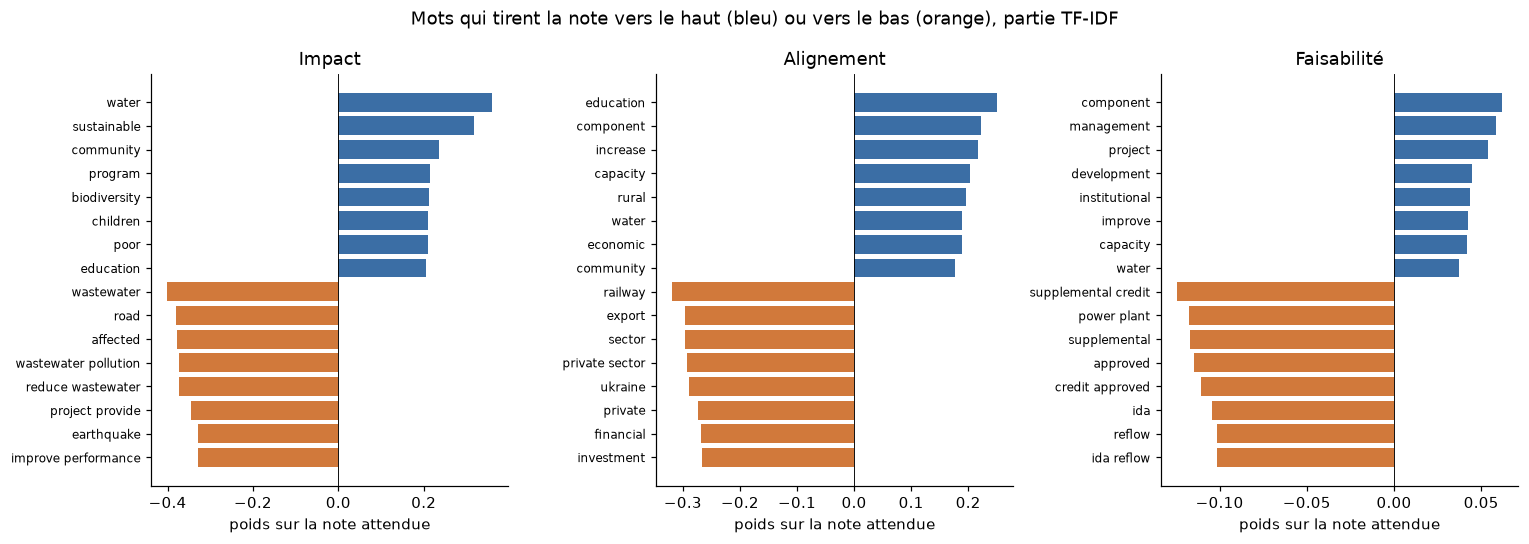

In [7]:
m = nlp.modele_extract()
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, c in zip(axes, C):
    mi = m.mots_influents(c, n=8)
    mots = [w for w, _ in mi["vers_le_bas"]][::-1] + [w for w, _ in mi["vers_le_haut"]][::-1]
    poids = [p for _, p in mi["vers_le_bas"]][::-1] + [p for _, p in mi["vers_le_haut"]][::-1]
    ax.barh(range(len(mots)), poids, color=["#d1793b" if p < 0 else "#3b6ea5" for p in poids])
    ax.set_yticks(range(len(mots)), mots, fontsize=8)
    ax.axvline(0, color="black", linewidth=0.6)
    ax.set(title=NOMS[c], xlabel="poids sur la note attendue")
fig.suptitle("Mots qui tirent la note vers le haut (bleu) ou vers le bas (orange), partie TF-IDF")
fig.tight_layout()
fig.savefig(FIGURES / "extract_mots_influents.png", bbox_inches="tight")

In [8]:
pd.DataFrame({NOMS[c]: {"positifs": ", ".join(nlp.MOTS_CLES[c]["plus"]), "négatifs": ", ".join(nlp.MOTS_CLES[c]["moins"]) or "(aucun)"}
              for c in C}).T

,positifs,négatifs
Impact,"poverty, poor, vulnerable, women, gender, health, nutrition, climate, environment, biodiversity, resilienc...","resettlement, displacement, pollution, deforestation"
Alignement,"strategy, national, government's, program, reform, priority, policy, sustainable development, climate, hum...",(aucun)
Faisabilité,"component, implementation, monitoring, evaluation, capacity, project management, unit, pilot, second phase...","conflict, crisis, emergency, fragile, post-war, postwar, weak capacity"


**Lecture.** La plupart des mots appris par TF-IDF, à partir des seules notes du LLM, sont cohérents avec la grille : *water*, *biodiversity*, *poor*, *children*, *community* tirent l'impact vers le haut ; *component*, *management*, *institutional*, *capacity* tirent la faisabilité vers le haut ; *education* tire l'alignement vers le haut.

D'autres trahissent les **habitudes du LLM** plutôt que la grille : *wastewater* et *road* font baisser l'impact (un projet d'assainissement a pourtant un impact social et environnemental), *private sector*, *financial* et *export* font baisser l'alignement. En faisabilité, ce sont des mots administratifs (*supplemental credit*, *IDA reflow*) qui font baisser la note : ils signalent surtout des textes anciens très courts, sans description de la mise en œuvre.

C'est l'intérêt de la combinaison : la liste de mots-clés, écrite à partir de la grille, corrige une partie de ces biais appris, et le recalage remet les notes sur l'échelle de référence.

## 6. Analyse des erreurs

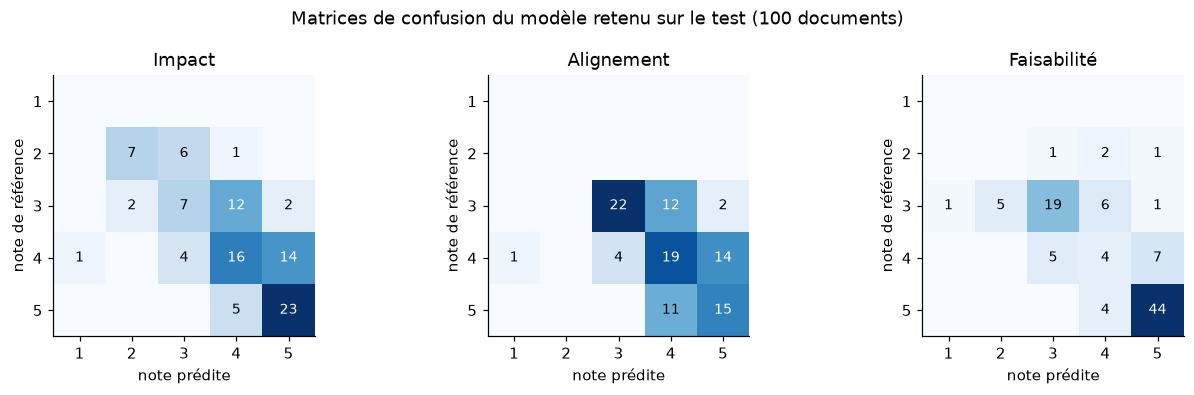

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, c in zip(axes, C):
    mc = confusion_matrix(vrai[c], modele("combinaison")[c], labels=[1, 2, 3, 4, 5])
    ax.imshow(mc, cmap="Blues")
    for i in range(5):
        for j in range(5):
            if mc[i, j]:
                ax.text(j, i, mc[i, j], ha="center", va="center", fontsize=9,
                        color="white" if mc[i, j] > mc.max() / 2 else "black")
    ax.set(title=NOMS[c], xlabel="note prédite", ylabel="note de référence",
           xticks=range(5), xticklabels=range(1, 6), yticks=range(5), yticklabels=range(1, 6))
fig.suptitle("Matrices de confusion du modèle retenu sur le test (100 documents)")
fig.tight_layout()
fig.savefig(FIGURES / "extract_confusion.png", bbox_inches="tight")

Matrices de confusion : la diagonale correspond aux notes exactes. Les erreurs sont presque toutes d'un seul point, sur une case voisine de la diagonale.

In [10]:
ecarts = pd.DataFrame({c: modele("combinaison")[c] - vrai[c] for c in C})
pd.DataFrame({
    "exact": (ecarts == 0).mean(),
    "à 1 point près": (ecarts.abs() <= 1).mean(),
    "écart de 2 ou plus": (ecarts.abs() >= 2).mean(),
    "note trop haute": (ecarts > 0).mean(),
    "note trop basse": (ecarts < 0).mean(),
}).rename(index=NOMS).mul(100).round(0)

,exact,à 1 point près,écart de 2 ou plus,note trop haute,note trop basse
Impact,53.0,96.0,4.0,35.0,12.0
Alignement,56.0,97.0,3.0,28.0,16.0
Faisabilité,67.0,95.0,5.0,18.0,15.0


In [11]:
pred["classe_longueur"] = pd.cut(pred.mots, [0, 30, 150, 10_000], labels=["moins de 30 mots", "30 à 150 mots", "plus de 150 mots"])
pred["erreur_moy"] = ecarts.abs().mean(axis=1)
pred.groupby("classe_longueur", observed=True).agg(documents=("id_projet", "size"), erreur_absolue_moyenne=("erreur_moy", "mean")).round(2)

,documents,erreur_absolue_moyenne
classe_longueur,,
moins de 30 mots,16,0.40
30 à 150 mots,20,0.47
plus de 150 mots,64,0.48


In [12]:
gros = []
for c in C:
    for k in ecarts.index[ecarts[c].abs() >= 2]:
        gros.append({"id_projet": pred.id_projet[k], "critère": NOMS[c], "référence": vrai[c][k],
                     "prédit": modele("combinaison")[c][k], "mots": pred.mots[k]})
gros = pd.DataFrame(gros).sort_values(["critère", "id_projet"])
print(len(gros), "erreurs de 2 points ou plus sur 300 notes")
gros

12 erreurs de 2 points ou plus sur 300 notes


,id_projet,critère,référence,prédit,mots
4,P152698,Alignement,3,5,319
5,P174017,Alignement,4,1,16
6,P179775,Alignement,3,5,1205
7,P038507,Faisabilité,3,1,20
8,P107921,Faisabilité,2,4,313
9,P172012,Faisabilité,2,4,173
10,P179775,Faisabilité,2,5,1205
11,P508608,Faisabilité,3,5,291
0,P099376,Impact,2,4,274
1,P152698,Impact,3,5,319


In [13]:
def detail(id_projet: str, critere: str) -> None:
    """Texte, notes et justification du modèle pour un document."""
    doc = (nlp.DOSSIER_DOCS / f"{id_projet}.txt").read_text(encoding="utf-8")
    texte = nlp.corps(doc)
    sortie = nlp.extract(doc)
    k = pred.index[pred.id_projet == id_projet][0]
    print(f"{id_projet} — {nlp.titre(doc)} ({len(texte.split())} mots)")
    print(f"  {NOMS[critere]} : référence {vrai[critere][k]}, modèle {sortie[critere]}, solde de mots-clés {nlp.solde_mots_cles(texte, critere)}")
    print(f"  justification : {sortie['justifications'][critere][:220]}")
    print(f"  début du texte : {texte[:300]}")
    print()

for id_projet, critere in [('P099376', 'impact_env_social'), ('P179775', 'faisabilite'), ('P172012', 'faisabilite'), ('P107921', 'faisabilite'), ('P168940', 'impact_env_social'), ('P174017', 'alignement_strategique')]:
    detail(id_projet, critere)

P099376 — Tax Administration Modernization Project (274 mots)
  Impact : référence 2, modèle 4, solde de mots-clés 1
  justification : IT development; and project management.
  début du texte : The project development objectives (PDOs) of the TAMP are to assist the General Department of Taxation (GDT) to strengthen governance in tax administration and to increase the level of voluntary compliance with the tax system by improving the effectiveness, efficiency, transparency and accountabilit

P179775 — Somalia Urban Resilience Project Phase II Second Additional Financing (1205 mots)
  Faisabilité : référence 2, modèle 5, solde de mots-clés 24
  justification : These activities help strengthen core municipal functions.-Component 3: Project Management and Capacity Building providing the overall project management costs, including monitoring and evaluation (M&E), as well as the c
  début du texte : To strengthen public service delivery capacity of local governments, increase access to clima

**Lecture.** 95 à 97 % des notes sont justes à un point près. Le modèle a tendance à **surnoter** (plus de notes trop hautes que trop basses, surtout en impact). Les 12 erreurs de 2 points ou plus ont quatre causes, toutes typiques d'une méthode fondée sur les mots :

1. **Mot ambigu.** P099376 (modernisation de l'administration fiscale) : le mot-clé *climate* est compté dans *investment climate*, qui désigne le climat des affaires et n'a rien d'environnemental. L'impact monte à 4 au lieu de 2. Un modèle par mots ne voit pas le sens de l'expression.
2. **Effet de longueur.** P179775 (1 205 mots, Somalie) : un texte long accumule les mots-clés (solde de 24). Les mots *conflict*, *crisis* et *emergency* sont bien comptés comme négatifs, mais ils sont noyés sous les dizaines de *component*, *monitoring* et *capacity*. La faisabilité monte à 5 alors que le texte décrit une famine et une urgence nationale.
3. **Signal absent du lexique.** P172012 (pêche au Liberia) : le texte dit que le projet initial était *overly ambitious* et que des travaux sont *no longer feasible*. P107921 (Afghanistan) évoque l'*uncertainty* et des élections. Aucun de ces mots n'est dans la liste négative, et TF-IDF ne les a pas appris à partir de 640 exemples. La faisabilité reste à 4.
4. **Textes courts notés 1.** P168940 (42 mots) et P174017 (16 mots) ne contiennent aucun mot-clé. Leur score combiné est plus bas que tout ce qui a été vu en validation, où les textes sont en moyenne plus longs, et tombe à 1. La grille aurait donné 3 (texte trop court pour juger). C'est la limite discutée plus bas : le modèle peut extrapoler vers une note que l'annotateur n'a jamais utilisée.

Les erreurs ne dépendent presque pas de la longueur du texte en moyenne (0,40 à 0,48 point d'erreur), mais les plus grosses viennent des deux extrêmes : textes très longs (point 2) et textes juste au-dessus de 15 mots (point 4).

## 7. Vitesse sur les 2 000 documents

L'agent appelle `extract` sur tous les projets analysés, et la démo est filmée sur un portable sans GPU. Le modèle est appris au premier appel, en environ 2 secondes, puis enregistré dans `models/nlp/` (ignoré par Git).

In [14]:
documents = nlp.charger_documents()
debut = time.perf_counter()
sorties = {i: nlp.extract(d) for i, d in documents.items()}
duree = time.perf_counter() - debut
print(f"extract sur {len(documents)} documents : {duree:.1f} s, soit {duree / len(documents) * 1000:.1f} ms par document")
repartition = pd.DataFrame({i: {c: s[c] for c in C} for i, s in sorties.items()}).T
repartition.apply(lambda s: s.value_counts().reindex(range(1, 6), fill_value=0)).rename(columns=NOMS)

extract sur 2000 documents : 10.0 s, soit 5.0 ms par document


,Impact,Alignement,Faisabilité
1,35,57,16
2,202,0,77
3,331,449,569
4,708,957,351
5,724,537,987


**Lecture.** Environ 10 secondes pour les 2 000 documents, justifications comprises : largement assez rapide pour l'agent. Le LLM, lui, aurait demandé environ 6 heures (11 s par document).

## 8. Limites

1. **Un seul annotateur.** La grille, la liste de mots-clés et les notes de référence viennent de la même personne. Les mots-clés partagent donc sa façon de lire la grille, ce qui les avantage par rapport au LLM. Un second annotateur sur une partie des documents permettrait de mesurer l'accord entre humains, qui est le vrai plafond atteignable.
2. **Notes jamais utilisées.** Aucune note de référence ne vaut 1, mais le modèle en donne quelques-unes par extrapolation (108 notes sur 6 000, soit 1,8 %, sur les 2 000 documents, et 3 notes sur 300 dans le test, des textes courts surtout). On a choisi de ne pas corriger après l'ouverture du test, pour garder un score de test propre. Correction possible pour une version suivante : borner les notes à celles utilisées par l'annotateur, et normaliser le solde de mots-clés par la longueur du texte.
3. **Effet de longueur et mots ambigus**, détaillés dans l'analyse des erreurs.
4. **Échantillons petits.** 160 documents de validation et 100 de test : les intervalles de confiance restent larges, et l'apport de TF-IDF par rapport aux mots-clés seuls n'est pas démontré.
5. **LLM petit.** `qwen2.5:3b` tourne sur un portable mais comprend la grille moins bien qu'un grand modèle. Des étiquettes d'apprentissage de meilleure qualité amélioreraient la partie TF-IDF.
6. **Les notes ne prédisent pas la rentabilité.** Les cibles du rôle 1 sont simulées sans lien avec les textes (`data/README.md`) : les notes qualitatives servent au classement multicritère, pas à prédire le risque.